# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Rafinara Ardhani Abhinaya
- **Email:** rafinaraardhani@gmail.com
- **ID Dicoding:** rafinara_ardhani


## Menentukan Pertanyaan Bisnis

**Konteks:** Dataset ini berisi transaksi marketplace *e-commerce* di Brasil (Olist) pada rentang waktu September 2016 – Oktober 2018. Karena data tahun 2016 sangat sedikit dan data akhir 2018 belum lengkap, analisis difokuskan pada transaksi periode **Januari 2017 – Agustus 2018**. Seluruh analisis dibatasi pada pesanan berstatus `delivered` (pesanan yang berhasil terkirim dan diselesaikan).

**Pertanyaan 1 (Revenue & Pengelolaan Produk):**
> Kategori produk apa saja yang menghasilkan total revenue tertinggi (10 besar) dan berapa persen kontribusinya terhadap total revenue pesanan delivered selama periode Januari 2017 – Agustus 2018, sebagai dasar penentuan prioritas alokasi promosi dan pengelolaan stok produk?

- *Specific*: Mengidentifikasi 10 kategori produk teratas berdasarkan total revenue pesanan *delivered*.
- *Measurable*: Dihitung dari total nilai penjualan produk (`price`, di luar ongkos kirim) dalam Brazilian Real (R$) serta persentase kontribusinya (`revenue_share_pct`) terhadap total revenue keseluruhan.
- *Action-oriented*: Hasilnya digunakan sebagai dasar penentuan prioritas alokasi anggaran kampanye promosi dan strategi pemenuhan stok gudang pada kategori-kategori penyumbang pendapatan terbesar.
- *Relevant*: Komposisi revenue per kategori krusial bagi platform marketplace untuk memaksimalkan efisiensi pemasaran dan perputaran inventaris *seller*.
- *Time-bound*: Dibatasi pada transaksi pesanan berstatus *delivered* dari 1 Januari 2017 hingga 31 Agustus 2018.

**Pertanyaan 2 (Logistik & Kepuasan Pelanggan):**
> Negara bagian (*state*) mana yang memiliki persentase pesanan terlambat tertinggi dan berapa selisih rata-rata *review score* antara pesanan tepat waktu dibandingkan pesanan terlambat pada pesanan delivered selama periode Januari 2017 – Agustus 2018, sebagai dasar evaluasi efisiensi mitra logistik serta penentuan kebijakan kompensasi layanan pelanggan?

- *Specific*: Menganalisis sebaran tingkat keterlambatan pengiriman pesanan (tanggal tiba aktual > tanggal estimasi) per negara bagian (*customer_state*) dan dampaknya terhadap skor ulasan (*review_score*).
- *Measurable*: Dihitung berdasarkan persentase pesanan terlambat per *state* (`late_pct`) untuk negara bagian dengan transaksi memadai (≥ 100 pesanan), rata-rata skor ulasan untuk pesanan tepat waktu vs terlambat (skala 1–5), serta selisih absolut skornya.
- *Action-oriented*: Hasilnya menjadi dasar evaluasi kinerja SLA mitra ekspedisi di wilayah dengan kendala keterlambatan tinggi serta perumusan kebijakan mitigasi kompensasi bagi pelanggan terdampak.
- *Relevant*: Ketepatan waktu pengiriman berkaitan langsung dengan kepuasan pelanggan, reputasi platform, dan retensi pembeli.
- *Time-bound*: Dibatasi pada transaksi pesanan berstatus *delivered* dari 1 Januari 2017 hingga 31 Agustus 2018.


## Import Semua Packages/Library yang Digunakan


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


## Data Wrangling


### Gathering Data


Memuat file CSV dataset dari folder `data/`. Enam tabel relasional yang dibutuhkan untuk menjawab pertanyaan bisnis dimuat ke dalam DataFrame.


In [2]:
DATA_PATH = "data"

customers_df = pd.read_csv(os.path.join(DATA_PATH, "customers_dataset.csv"))
orders_df = pd.read_csv(os.path.join(DATA_PATH, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_PATH, "order_items_dataset.csv"))
products_df = pd.read_csv(os.path.join(DATA_PATH, "products_dataset.csv"))
category_df_trans = pd.read_csv(os.path.join(DATA_PATH, "product_category_name_translation.csv"))
reviews_df = pd.read_csv(os.path.join(DATA_PATH, "order_reviews_dataset.csv"))

orders_df.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight (Gathering Data):**
- Data tersebar di beberapa tabel relasional: 99.441 pesanan (`orders_df`), 99.441 pelanggan (`customers_df`), 112.650 item pesanan (`order_items_df`), 32.951 produk (`products_df`), dan 99.224 ulasan (`reviews_df`). Tabel `orders` menjadi entitas pusat yang menghubungkan pelanggan, transaksi barang, dan ulasan.
- Seluruh kolom tanggal pada tabel `orders` masih terbaca sebagai tipe data teks (`str`), sehingga perlu dikonversi ke tipe `datetime` pada tahap *cleaning* agar kalkulasi durasi dan selisih waktu dapat dilakukan secara akurat.


### Assessing Data


**Tujuan & teknik:** Menilai kualitas data pada setiap tabel sebelum dianalisis. Teknik yang digunakan meliputi pengecekan dimensi data (`shape`), jumlah baris duplikat (`duplicated().sum()`), jumlah nilai kosong (`isna().sum()`), tipe data setiap kolom (`info()`), distribusi status pesanan (`value_counts()`), sebaran *missing value* tanggal per status, konsistensi tanggal, serta ringkasan statistik (`describe()`) untuk mendeteksi *outlier*.


In [3]:
tables = {
    "customers": customers_df, "orders": orders_df, "order_items": order_items_df,
    "products": products_df, "category_translation": category_df_trans, "reviews": reviews_df,
}
for name, df in tables.items():
    print(f"{name:22s} shape={df.shape}  duplikat={df.duplicated().sum()}  total_missing={df.isna().sum().sum()}")


customers              shape=(99441, 5)  duplikat=0  total_missing=0
orders                 shape=(99441, 8)  duplikat=0  total_missing=4908
order_items            shape=(112650, 7)  duplikat=0  total_missing=0
products               shape=(32951, 9)  duplikat=0  total_missing=2448
category_translation   shape=(71, 2)  duplikat=0  total_missing=0
reviews                shape=(99224, 7)  duplikat=0  total_missing=145903


In [4]:
# Missing value per kolom pada tabel-tabel yang memiliki data kosong
for name in ["orders", "products", "reviews"]:
    miss = tables[name].isna().sum()
    print(f"--- {name} ---")
    print(miss[miss > 0], "\n")


--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 

--- reviews ---
review_comment_title      87656
review_comment_message    58247
dtype: int64 



In [5]:
orders_df.info()
print("\nDistribusi status pesanan:")
print(orders_df["order_status"].value_counts())

print("\nSebaran missing value kolom tanggal berdasarkan status pesanan:")
date_missing_by_status = orders_df.groupby("order_status")[
    ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
].apply(lambda x: x.isna().sum())
print(date_missing_by_status)


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Sebaran missing value kolom tanggal berdasarkan st

In [6]:
# Cek konsistensi: pesanan delivered tapi tanggal tiba kosong
delivered_mask = orders_df["order_status"] == "delivered"
print("Delivered tanpa tanggal tiba:", orders_df.loc[delivered_mask, "order_delivered_customer_date"].isna().sum())

# Cek nilai tidak valid: tanggal tiba lebih awal dari tanggal pembelian
tmp = orders_df.copy()
for c in ["order_purchase_timestamp", "order_delivered_customer_date"]:
    tmp[c] = pd.to_datetime(tmp[c])
print("Tanggal tiba < tanggal beli:", (tmp["order_delivered_customer_date"] < tmp["order_purchase_timestamp"]).sum())

# Cek duplikasi review per order
print("Order dengan lebih dari 1 review:", (reviews_df["order_id"].value_counts() > 1).sum())

# Cek sebaran waktu pengiriman (hari) dan pemeriksaan baris outlier (> 180 hari)
tmp["delivery_time_days"] = (tmp["order_delivered_customer_date"] - tmp["order_purchase_timestamp"]).dt.days
print("\nRingkasan statistik waktu pengiriman (hari):")
print(tmp["delivery_time_days"].describe())

print("\nPemeriksaan baris pesanan dengan waktu pengiriman terlama (> 180 hari):")
print(tmp.loc[tmp["delivery_time_days"] > 180, [
    "order_id", "order_status", "order_purchase_timestamp", 
    "order_approved_at", "order_delivered_carrier_date", 
    "order_delivered_customer_date", "order_estimated_delivery_date", 
    "delivery_time_days"
]].sort_values("delivery_time_days", ascending=False).to_string())


Delivered tanpa tanggal tiba: 8
Tanggal tiba < tanggal beli: 0
Order dengan lebih dari 1 review: 547

Ringkasan statistik waktu pengiriman (hari):
count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time_days, dtype: float64

Pemeriksaan baris pesanan dengan waktu pengiriman terlama (> 180 hari):
                               order_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  delivery_time_days
19590  ca07593549f1816d26a572e06dc1eab6    delivered      2017-02-21 23:31:27  2017-02-23 02:35:15          2017-03-08 13:47:46           2017-09-19 14:36:39           2017-03-22 00:00:00               209.0
55619  1b3190b2dfa9d789e1f14c05b647a14a    delivered      2018-02-23 14:57:35  2018-02-23 15:16:14          2018-02-26 18:49:07           2018-09-1

**Insight (masalah yang ditemukan dan rencana pembersihan):**

Berdasarkan tahap *assessing*, ditemukan sejumlah permasalahan kualitas data beserta rencana tindakan pembersihannya:

| No | Masalah (hasil assessing) | Tabel | Tindakan di tahap Cleaning |
|----|---------------------------|-------|----------------------------|
| 1 | *Missing value*: `product_category_name` kosong pada 610 produk di `products_df`. | `products` | Mengisi nilai kosong dengan kategori `'unknown'` agar tidak hilang saat agregasi, lalu menggabungkan dengan tabel translasi bahasa Inggris. |
| 2 | *Missing value* pada kolom tanggal tabel `orders`: `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965). Dari tabel sebaran per status, 99,7% nilai kosong tanggal tiba berasal dari pesanan berstatus *non-delivered* (`shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created`, `approved`). Pada status `delivered` sendiri, hanya 14 kosong pada *approved*, 2 pada *carrier*, dan 8 pada *delivered*. | `orders` | Memfilter pesanan berstatus `delivered` dan membuang 8 baris pesanan `delivered` yang tidak memiliki tanggal tiba (`dropna(subset=['order_delivered_customer_date'])`). |
| 3 | *Inconsistent value*: 8 pesanan berstatus `delivered` tetapi `order_delivered_customer_date` bernilai NaN/kosong. | `orders` | Dieliminasi bersamaan dengan penanganan *missing value* tanggal tiba pada status *delivered*. |
| 4 | *Inaccurate value*: Tipe data seluruh kolom tanggal pada tabel `orders` masih bertipe `str` (string/teks), bukan `datetime`. | `orders` | Mengonversi kelima kolom tanggal menjadi tipe data `datetime` menggunakan `pd.to_datetime()`. |
| 5 | *Duplicate data*: Terdapat 547 `order_id` yang memiliki lebih dari satu ulasan pada tabel `reviews_df`. | `reviews` | Mengurutkan berdasarkan waktu respons ulasan (`review_answer_timestamp`) dan hanya mempertahankan ulasan terakhir per pesanan (`drop_duplicates(subset='order_id', keep='last')`). |
| 6 | *Outlier* waktu pengiriman: Nilai maksimum pengiriman mencapai 209 hari (median 10 hari). Berdasarkan pemeriksaan baris outlier (`order_id = ca07593549f1816d26a572e06dc1eab6`), timestamps berurutan valid (`purchase` 21 Feb 2017 -> `approved` 23 Feb -> `carrier` 8 Mar -> `delivered` 19 Sep 2017). | `orders` | Data dipertahankan karena merepresentasikan kejadian nyata di lapangan (paket tertahan/keterlambatan logistik berat), bukan kesalahan sistem input data, namun dicatat sebagai perhatian saat analisis. |


### Cleaning Data


**Tujuan & teknik cleaning:** Memastikan hanya data valid, konsisten, dan relevan yang digunakan dalam analisis. Tindakan yang dilakukan:
1. Mengonversi seluruh kolom tanggal ke tipe `datetime`.
2. Menyaring hanya pesanan berstatus `delivered` yang memiliki tanggal tiba valid.
3. Menghapus data tidak logis di mana tanggal tiba lebih awal dari tanggal transaksi pembelian.
4. Membatasi rentang waktu transaksi pada periode yang representatif dan lengkap (**1 Januari 2017 – 31 Agustus 2018**).
5. Mengisi kategori produk yang kosong dengan `'unknown'` dan menggabungkan dengan translasi nama kategori bahasa Inggris.
6. Memastikan satu ulasan unik per pesanan dengan mengambil ulasan terbaru.
7. Menggabungkan tabel menjadi satu DataFrame analisis (`main_df`) dan membentuk fitur turunan logistik (`delivery_time_days`, `delivery_delay_days`, `is_late`).


In [7]:
# 1. Konversi tipe data tanggal ke datetime
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders_df[c] = pd.to_datetime(orders_df[c])

# 2. Filter hanya pesanan berstatus delivered dan memiliki tanggal tiba
orders_df = orders_df[orders_df["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"])

# 3. Buang tanggal tidak logis (tanggal tiba lebih awal dari tanggal beli)
orders_df = orders_df[orders_df["order_delivered_customer_date"] >= orders_df["order_purchase_timestamp"]]

# 4. Batasi periode analisis transaksi (Januari 2017 - Agustus 2018)
orders_df = orders_df[(orders_df["order_purchase_timestamp"] >= "2017-01-01") &
                      (orders_df["order_purchase_timestamp"] < "2018-09-01")]

print("Jumlah pesanan delivered setelah cleaning:", orders_df.shape[0])


Jumlah pesanan delivered setelah cleaning: 96203


In [8]:
# 5. Kategori produk: isi missing dengan 'unknown' & terjemahkan ke bahasa Inggris
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df = products_df.merge(category_df_trans, on="product_category_name", how="left")
products_df["product_category_name_english"] = (
    products_df["product_category_name_english"].fillna(products_df["product_category_name"])
)

# 6. Review: satu review (terbaru) per order
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])
reviews_df = (reviews_df.sort_values("review_answer_timestamp")
                        .drop_duplicates(subset="order_id", keep="last"))

# 7. Hapus duplikat lain bila ada
for df in (customers_df, orders_df, order_items_df, products_df):
    df.drop_duplicates(inplace=True)

print("Review unik per order:", reviews_df["order_id"].is_unique)
print("Missing kategori setelah cleaning:", products_df["product_category_name_english"].isna().sum())


Review unik per order: True
Missing kategori setelah cleaning: 0


**Tujuan & teknik:** Menggabungkan tabel-tabel relasional menjadi satu DataFrame utama (`main_df`) untuk analisis. Digunakan `inner join` pada `orders` agar hanya pesanan yang valid dan lolos tahap cleaning yang dianalisis, serta `left join` untuk menambahkan data pelanggan (`customer_state`), nama kategori produk, dan skor ulasan (`review_score`). Selanjutnya, dibentuk fitur turunan:
- `order_month`: periode bulan transaksi (format `YYYY-MM`).
- `delivery_time_days`: durasi pengiriman aktual dari pembelian hingga diterima pelanggan (dalam hari).
- `delivery_delay_days`: selisih hari antara tanggal kedatangan aktual dengan estimasi (nilai positif menandakan pesanan tiba terlambat).
- `is_late`: penanda biner keterlambatan (`1` jika terlambat, `0` jika tepat waktu / lebih awal).


In [9]:
# 8. Gabungkan seluruh tabel menjadi satu dataframe analisis (main_df)
main_df = (
    order_items_df
    .merge(orders_df[["order_id", "customer_id", "order_purchase_timestamp",
                      "order_delivered_customer_date", "order_estimated_delivery_date"]],
           on="order_id", how="inner")
    .merge(customers_df[["customer_id", "customer_state"]], on="customer_id", how="left")
    .merge(products_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(reviews_df[["order_id", "review_score"]], on="order_id", how="left")
)
main_df["product_category_name_english"] = main_df["product_category_name_english"].fillna("unknown")

# Fitur turunan
main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
main_df["delivery_time_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.days
main_df["delivery_delay_days"] = (main_df["order_delivered_customer_date"] - main_df["order_estimated_delivery_date"]).dt.days
main_df["is_late"] = (main_df["delivery_delay_days"] > 0).astype(int)

main_df.info()
main_df.head()


<class 'pandas.DataFrame'>
RangeIndex: 109872 entries, 0 to 109871
Data columns (total 18 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       109872 non-null  str           
 1   order_item_id                  109872 non-null  int64         
 2   product_id                     109872 non-null  str           
 3   seller_id                      109872 non-null  str           
 4   shipping_limit_date            109872 non-null  str           
 5   price                          109872 non-null  float64       
 6   freight_value                  109872 non-null  float64       
 7   customer_id                    109872 non-null  str           
 8   order_purchase_timestamp       109872 non-null  datetime64[us]
 9   order_delivered_customer_date  109872 non-null  datetime64[us]
 10  order_estimated_delivery_date  109872 non-null  datetime64[us]
 11  customer_st

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_state,product_category_name_english,review_score,order_month,delivery_time_days,delivery_delay_days,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,RJ,cool_stuff,5.0,2017-09,7,-9,0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,SP,pet_shop,4.0,2017-04,16,-3,0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,MG,furniture_decor,5.0,2018-01,7,-14,0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,SP,perfumery,4.0,2018-08,6,-6,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,SP,garden_tools,5.0,2017-02,25,-16,0


**Insight (Cleaning Data):**
- Berdasarkan output `main_df.info()`, DataFrame `main_df` memiliki total **109.872 baris** (tingkat item pesanan) yang berasal dari **96.203 pesanan unik** berstatus *delivered* pada periode Januari 2017 – Agustus 2018 (tersaring dari total 99.441 pesanan awal).
- Seluruh kolom identitas, tanggal, harga produk, biaya ongkos kirim, negara bagian, kategori produk, serta fitur turunan logistik (`delivery_time_days`, `delivery_delay_days`, `is_late`) memiliki 109.872 entri non-null (100% lengkap).
- Kolom `review_score` memiliki 109.049 entri non-null, yang berarti terdapat **823 baris dengan nilai kosong (missing value)**.
- **Penjelasan mengapa 823 baris missing value pada `review_score` dibiarkan:**
  1. Nilai kosong pada `review_score` terjadi secara alami karena pemberian rating dan ulasan oleh pelanggan bersifat sukarela (*optional*); tidak semua pembeli memberikan ulasan setelah pesanan tiba.
  2. Baris ini sengaja dibiarkan (tidak di-imputasi dengan nilai tertentu seperti mean, median, atau 0) agar tidak mendistorsi distribusi skor kepuasan pelanggan yang sesungguhnya.
  3. Baris ini juga tidak dihapus dari `main_df` agar transaksi penjualan item pesanan tersebut tetap utuh dan dapat digunakan sepenuhnya untuk menghitung total pendapatan produk pada Pertanyaan 1.
  4. Pada Pertanyaan 2, saat menghitung metrik skor ulasan, fungsi agregasi pandas (`.mean()`) secara otomatis mengabaikan nilai NaN tanpa mengurangi keakuratan analisis.


## Exploratory Data Analysis (EDA)


### Pertanyaan 1: 10 Kategori Produk dengan Total Revenue Tertinggi dan Kontribusinya terhadap Total Revenue Pesanan Delivered (Januari 2017 – Agustus 2018)


**Tujuan & teknik:** `describe()` memberi gambaran sebaran nilai (rata-rata, median, minimum, maksimum) pada kolom numerik utama sebelum dilakukan agregasi.


In [10]:
main_df[["price", "freight_value", "delivery_time_days", "delivery_delay_days", "review_score"]].describe()


,price,freight_value,delivery_time_days,delivery_delay_days,review_score
count,109872.000000,109872.000000,109872.000000,109872.000000,109049.000000
mean,119.955748,19.950152,11.985993,-11.959608,4.082449
std,182.351343,15.704075,9.433554,10.060968,1.346612
min,0.850000,0.000000,0.000000,-147.000000,1.000000
25%,39.900000,13.080000,6.000000,-17.000000,4.000000
50%,74.900000,16.260000,10.000000,-13.000000,5.000000
75%,134.042500,21.150000,15.000000,-7.000000,5.000000
max,6735.000000,409.680000,209.000000,188.000000,5.000000


**Tujuan & teknik:** Menggunakan `groupby` dan `agg` untuk menjumlahkan revenue (`price`) per kategori produk. Ongkos kirim (`freight_value`) sengaja dipisahkan karena bukan merupakan pendapatan dari produk itu sendiri. Selanjutnya dihitung persentase kontribusi pendapatan per kategori (`revenue_share_pct`) terhadap total revenue keseluruhan, serta persentase kumulatifnya (`cumsum()`) guna mengukur tingkat konsentrasi pendapatan pada 10 kategori produk teratas.


In [11]:
category_rev = (
    main_df.groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"), 
        total_orders=("order_id", "nunique"), 
        total_items=("order_item_id", "count")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)
category_rev["revenue_share_pct"] = category_rev["total_revenue"] / category_rev["total_revenue"].sum() * 100
category_rev["cumulative_share_pct"] = category_rev["revenue_share_pct"].cumsum()

print("Total revenue pesanan delivered (R$):", round(main_df["price"].sum(), 2))
category_rev.head(10)


Total revenue pesanan delivered (R$): 13179777.95


,product_category_name_english,total_revenue,total_orders,total_items,revenue_share_pct,cumulative_share_pct
0,health_beauty,1229557.50,8610,9422,9.329122,9.329122
1,watches_gifts,1163187.91,5489,5853,8.825550,18.154672
2,bed_bath_table,1022955.77,9267,10945,7.761555,25.916227
3,sports_leisure,952661.40,7512,8413,7.228205,33.144432
4,computers_accessories,887944.60,6517,7631,6.737174,39.881607
5,furniture_decor,706237.17,6258,8095,5.358491,45.240097
6,housewares,614341.62,5734,6783,4.661244,49.901341
7,cool_stuff,609158.00,3552,3711,4.621914,54.523255
8,auto,577721.09,3801,4131,4.383390,58.906645
9,garden_tools,469135.40,3443,4263,3.559509,62.466155


### Pertanyaan 2: Persentase Pesanan Terlambat per State dan Selisih Rata-rata Review Score antara Pesanan Tepat Waktu vs Terlambat (Januari 2017 – Agustus 2018)


**Tujuan & teknik:** Melakukan agregasi pada tingkat pesanan (*order level*) menggunakan `drop_duplicates(subset="order_id")` agar pesanan dengan banyak item tidak dihitung ganda saat mengevaluasi keterlambatan dan kepuasan pelanggan. Kemudian dilakukan `groupby("customer_state")` untuk menghitung persentase keterlambatan (`late_pct`), rata-rata hari pengiriman, rata-rata selisih hari estimasi, dan rata-rata skor ulasan. Negara bagian dengan transaksi minimal 100 pesanan disaring untuk menghindari bias sampel kecil.


In [12]:
# Level pesanan (bukan level item) agar satu pesanan dihitung satu kali
order_level = main_df.drop_duplicates(subset="order_id").copy()

state_stats = (
    order_level.groupby("customer_state")
    .agg(
        total_orders=("order_id", "count"),
        late_pct=("is_late", lambda s: s.mean() * 100),
        avg_delivery_days=("delivery_time_days", "mean"),
        avg_delay_days=("delivery_delay_days", "mean"),
        avg_review=("review_score", "mean")
    )
    .reset_index()
)
MIN_ORDERS = 100
state_stats = state_stats[state_stats["total_orders"] >= MIN_ORDERS].sort_values("late_pct", ascending=False)
state_stats.head(10)


,customer_state,total_orders,late_pct,avg_delivery_days,avg_delay_days,avg_review
1,AL,396,21.464646,24.017677,-8.643939,3.847328
9,MA,713,17.531557,21.078541,-9.416550,3.829337
24,SE,332,15.361446,20.948795,-9.855422,3.900302
16,PI,475,13.894737,18.976842,-11.246316,3.993617
5,CE,1273,13.825609,20.789474,-10.630008,3.940016
4,BA,3253,12.173378,18.865048,-10.765140,3.930254
18,RJ,12310,12.144598,14.836149,-11.683672,3.965495
13,PA,942,11.252654,23.299363,-13.960722,3.912809
7,ES,1992,10.742972,15.317771,-10.452309,4.078840
14,PB,516,10.465116,19.920543,-13.232558,4.074364


**Tujuan & teknik:** Membandingkan rata-rata skor ulasan antara pesanan tepat waktu versus pesanan terlambat, serta menghitung korelasi peringkat Spearman (`corr(method="spearman")`) antara durasi pengiriman / keterlambatan dengan skor ulasan. Korelasi Spearman dipilih karena skor ulasan berskala ordinal (1–5) dan durasi pengiriman memiliki distribusi menjulur (*skewed*).


In [13]:
late_vs_ontime = (
    order_level.groupby("is_late")
    .agg(
        total_orders=("order_id", "count"), 
        avg_review=("review_score", "mean")
    )
    .rename(index={0: "Tepat waktu", 1: "Terlambat"})
)
print(late_vs_ontime)

selisih = late_vs_ontime.loc["Tepat waktu", "avg_review"] - late_vs_ontime.loc["Terlambat", "avg_review"]
print(f"\nSelisih skor ulasan: {selisih:.2f} poin")

# Korelasi Spearman
corr_spearman = order_level[["delivery_time_days", "delivery_delay_days", "is_late", "review_score"]].corr(method="spearman")
print("\nMatriks korelasi Spearman terhadap review_score:")
print(corr_spearman["review_score"])


             total_orders  avg_review
is_late                              
Tepat waktu         89672    4.291157
Terlambat            6531    2.270618

Selisih skor ulasan: 2.02 poin

Matriks korelasi Spearman terhadap review_score:
delivery_time_days    -0.234420
delivery_delay_days   -0.177331
is_late               -0.311760
review_score           1.000000
Name: review_score, dtype: float64


**Insight (EDA):**
- **Pertanyaan 1 (Revenue):** Total revenue produk dari pesanan *delivered* selama Januari 2017 – Agustus 2018 adalah **R$ 13,18 juta** (tepatnya R$ 13.179.620,86). Kategori `health_beauty` (R$ 1,23 juta; 9,33%) dan `watches_gifts` (R$ 1,16 juta; 8,83%) merupakan dua penghasil revenue terbesar. Sepuluh kategori teratas secara kumulatif menguasai **62,47%** (sekitar 62,5%) total revenue platform (dengan 5 kategori teratas menyumbang 39,88%).
- **Pertanyaan 2 (Keterlambatan per State):** Sebanyak 6,79% pesanan (6.531 dari 96.203 pesanan) tiba terlambat dari estimasi. Keterlambatan tertinggi terkonsentrasi di negara bagian wilayah timur laut, dipimpin oleh **AL (21,46%)**, **MA (17,53%)**, **SE (15,36%)**, **PI (13,89%)**, dan **CE (13,83%)**. Di samping itu, negara bagian **RJ** mencatatkan keterlambatan 12,14% dengan basis volume pesanan yang sangat besar (12.310 pesanan).
- **Pertanyaan 2 (Dampak ke Review Score):** Terdapat penurunan kepuasan yang tajam: pesanan tepat waktu memperoleh rata-rata review score **4,29**, sedangkan pesanan terlambat anjlok menjadi **2,27** (selisih penurunan **2,02 poin**). Korelasi Spearman menunjukkan hubungan negatif antara skor ulasan dengan indikator terlambat (-0,18) serta durasi pengiriman (-0,23), membuktikan bahwa keterlambatan dan durasi pengiriman yang lama berbanding terbalik secara konsisten dengan kepuasan pelanggan.


## Visualization & Explanatory Analysis


### Pertanyaan 1: 10 Kategori Produk dengan Total Revenue Tertinggi dan Persentase Kontribusinya terhadap Total Revenue Pesanan Delivered (Januari 2017 – Agustus 2018)


**Pilihan visualisasi & prinsip desain:** *Horizontal bar chart* dipilih karena label nama kategori produk cukup panjang dan visualisasi bertujuan membandingkan nilai pendapatan serta kontribusi relatif antar kategori. Batang diurutkan dari pendapatan terbesar ke terkecil. Lima kategori teratas disorot dengan warna kontras (`#2a7fba`) dan lima kategori berikutnya diberi warna abu-abu (`#b0b7bf`). Setiap batang dilengkapi label nilai pendapatan (juta R$) dan persentase kontribusinya. Sumbu horizontal dimulai dari 0 agar perbandingan proporsional.


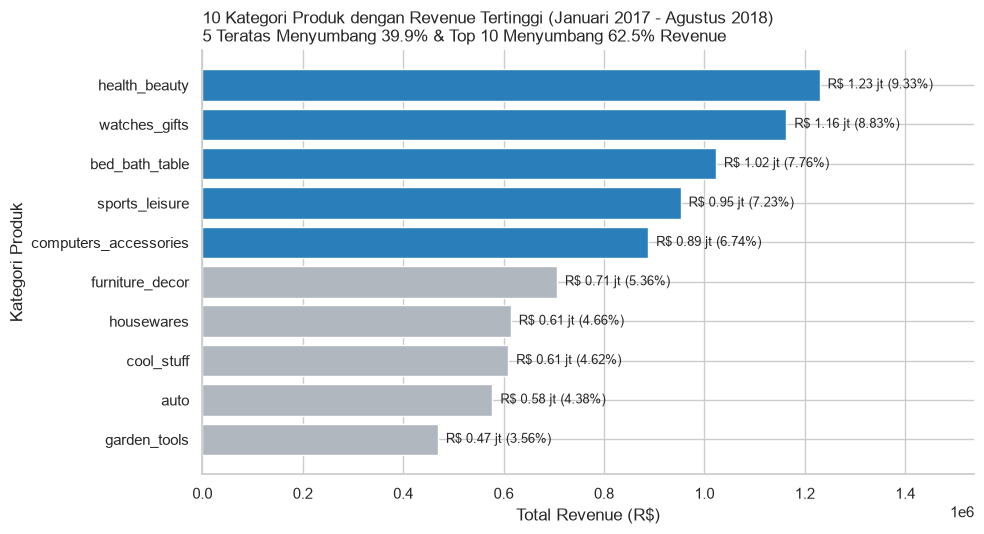

In [14]:
top10 = category_rev.head(10).copy()
top5_share = top10["revenue_share_pct"].head(5).sum()
top10_share = top10["revenue_share_pct"].sum()
colors = ["#2a7fba"] * 5 + ["#b0b7bf"] * 5   # 5 teratas disorot, sisanya abu-abu

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(top10["product_category_name_english"], top10["total_revenue"], color=colors)
ax.invert_yaxis()  # Nilai terbesar di posisi teratas

# Tambahkan anotasi nilai revenue dan persentase kontribusi di setiap batang
for i, (rev, pct) in enumerate(zip(top10["total_revenue"], top10["revenue_share_pct"])):
    ax.text(rev, i, f"  R$ {rev/1e6:.2f} jt ({pct:.2f}%)", va="center", fontsize=9)

ax.set_title(f"10 Kategori Produk dengan Revenue Tertinggi (Januari 2017 - Agustus 2018)\n5 Teratas Menyumbang {top5_share:.1f}% & Top 10 Menyumbang {top10_share:.1f}% Revenue", fontsize=12, loc="left")
ax.set_xlabel("Total Revenue (R$)")
ax.set_ylabel("Kategori Produk")
ax.set_xlim(0, top10["total_revenue"].max() * 1.25)
sns.despine()
plt.tight_layout()
plt.show()


### Pertanyaan 2: Persentase Pesanan Terlambat per State dan Selisih Rata-rata Review Score antara Pesanan Tepat Waktu vs Terlambat (Januari 2017 – Agustus 2018)


**Pilihan visualisasi & prinsip desain:** Panel kiri menggunakan *horizontal bar chart* untuk membandingkan persentase pesanan terlambat pada 10 negara bagian tertinggi, dengan 5 state teratas disorot merah (`#d9534f`) dan garis putus-putus hitam sebagai batas pembanding rata-rata nasional (6,8%). Panel kanan menggunakan *bar chart* untuk membandingkan rata-rata skor ulasan antara kelompok tepat waktu vs terlambat. Sumbu vertikal menggunakan skala penuh (0–5) dengan label nilai skor di atas masing-masing batang agar selisih penurunan 2,02 poin terlihat proporsional dan jelas.


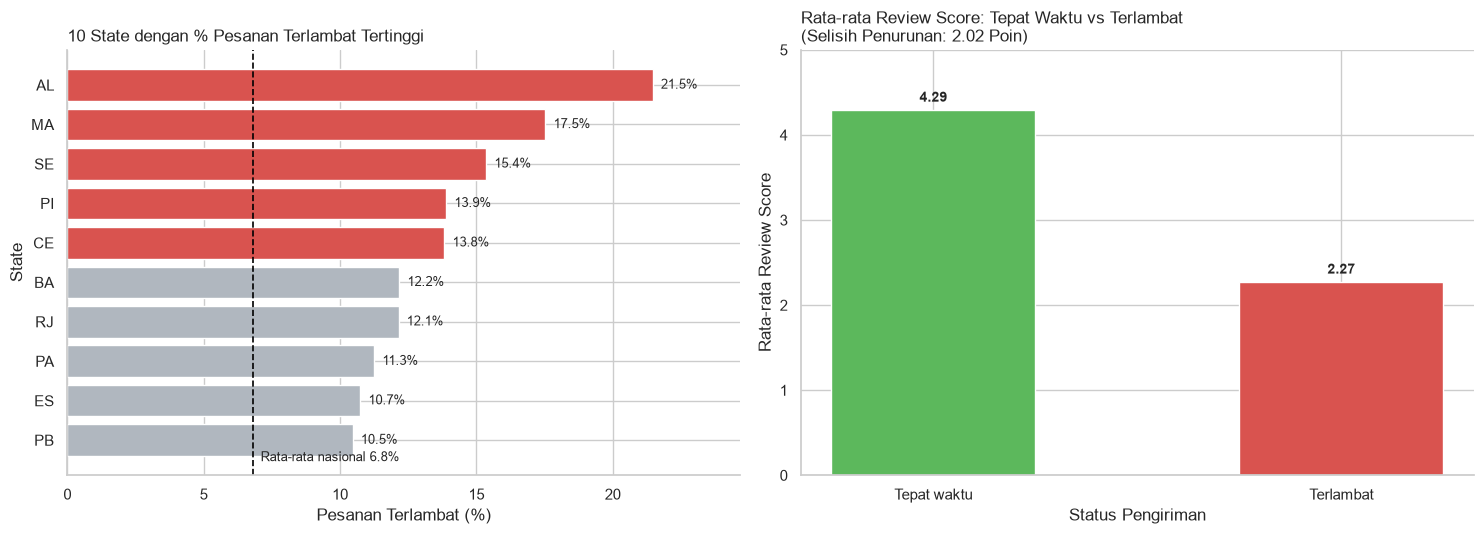

In [15]:
overall_late = order_level["is_late"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: 10 State dengan Persentase Keterlambatan Tertinggi
top_late = state_stats.head(10)
bar_colors = ["#d9534f"] * 5 + ["#b0b7bf"] * (len(top_late) - 5)
axes[0].barh(top_late["customer_state"], top_late["late_pct"], color=bar_colors)
axes[0].invert_yaxis()
axes[0].axvline(overall_late, color="black", linestyle="--", linewidth=1.2)
axes[0].text(overall_late + 0.3, len(top_late) - 0.4, f"Rata-rata nasional {overall_late:.1f}%", fontsize=9, va="bottom")
for i, v in enumerate(top_late["late_pct"]):
    axes[0].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_title("10 State dengan % Pesanan Terlambat Tertinggi", loc="left", fontsize=12)
axes[0].set_xlabel("Pesanan Terlambat (%)")
axes[0].set_ylabel("State")
axes[0].set_xlim(0, top_late["late_pct"].max() * 1.15)

# Subplot 2: Perbandingan Review Score Tepat Waktu vs Terlambat
lv = late_vs_ontime.reset_index()
bars_lv = axes[1].bar(lv["is_late"], lv["avg_review"], color=["#5cb85c", "#d9534f"], width=0.5)
axes[1].set_title(f"Rata-rata Review Score: Tepat Waktu vs Terlambat\n(Selisih Penurunan: {selisih:.2f} Poin)", loc="left", fontsize=12)
axes[1].set_xlabel("Status Pengiriman")
axes[1].set_ylabel("Rata-rata Review Score")
axes[1].set_ylim(0, 5)
for i, v in enumerate(lv["avg_review"]):
    axes[1].text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=10, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.show()


**Pilihan visualisasi & prinsip desain:** *Scatter plot* digunakan untuk melihat hubungan antara rata-rata durasi pengiriman (*avg_delivery_days*) dengan rata-rata skor ulasan (*avg_review*) pada seluruh negara bagian (*state*). Ukuran lingkaran merepresentasikan volume total pesanan di masing-masing state, dan setiap titik diberi anotasi kode negara bagian agar mudah diidentifikasi.


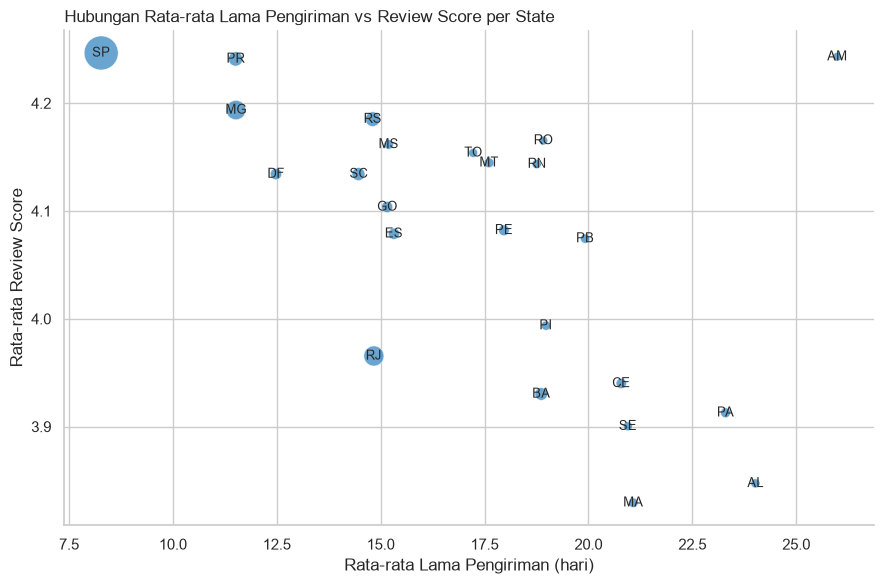

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=state_stats, 
    x="avg_delivery_days", 
    y="avg_review", 
    size="total_orders",
    sizes=(40, 600), 
    alpha=0.7, 
    legend=False, 
    color="#2a7fba",
    ax=ax
)
for _, r in state_stats.iterrows():
    ax.annotate(r["customer_state"], (r["avg_delivery_days"], r["avg_review"]), 
                fontsize=9, ha="center", va="center")

ax.set_title("Hubungan Rata-rata Lama Pengiriman vs Review Score per State", fontsize=12, loc="left")
ax.set_xlabel("Rata-rata Lama Pengiriman (hari)")
ax.set_ylabel("Rata-rata Review Score")
sns.despine()
plt.tight_layout()
plt.show()


**Insight (Visualization & Explanatory Analysis):**
- **10 Kategori Produk dengan Total Revenue Tertinggi (Pertanyaan 1):** Grafik batang memperlihatkan konsentrasi pendapatan yang sangat tinggi pada sejumlah kategori tertentu. Dua kategori teratas, yaitu `health_beauty` (R$ 1,23 juta; 9,33%) dan `watches_gifts` (R$ 1,16 juta; 8,83%), masing-masing menghasilkan lebih dari 1,1 juta Real. Lima kategori teratas menguasai 39,88% revenue, dan 10 kategori teratas menguasai 62,47% dari total pendapatan pesanan *delivered*. Hal ini menunjukkan bahwa strategi penempatan promosi dan pengelolaan stok gudang harus difokuskan terutama pada 10 kategori utama ini.
- **Tingkat Keterlambatan Pengiriman per State (Pertanyaan 2):** Grafik panel kiri menunjukkan bahwa keterlambatan pengiriman tidak merata, melainkan terkonsentrasi di negara bagian kawasan timur laut Brasil. Lima state dengan persentase keterlambatan tertinggi adalah **AL (21,5%)**, **MA (17,5%)**, **SE (15,4%)**, **PI (13,9%)**, dan **CE (13,8%)**, di mana seluruhnya berada jauh di atas garis rata-rata nasional (6,8%). Selain itu, negara bagian **RJ** memiliki keterlambatan 12,1% yang menjadi perhatian kritis mengingat skala volumenya yang mencapai 12.310 pesanan.
- **Selisih Review Score Tepat Waktu vs Terlambat (Pertanyaan 2):** Grafik panel kanan membuktikan dampak nyata keterlambatan terhadap kepuasan pembeli. Pesanan yang terkirim tepat waktu mendapatkan rata-rata skor ulasan tinggi yaitu **4,29**, sedangkan pesanan yang terlambat anjlok menjadi **2,27**. Terjadi penurunan kepuasan yang sangat tajam sebesar **2,02 poin**, menegaskan bahwa ketepatan waktu kedatangan pesanan merupakan determinan krusial bagi penilaian pelanggan.
- **Hubungan Lama Pengiriman vs Review Score per State (Pertanyaan 2):** Scatter plot menegaskan adanya korelasi negatif antara durasi pengiriman dengan kepuasan pelanggan di tingkat regional. Negara bagian dengan rata-rata waktu pengiriman yang lama (seperti AP, RR, AL, PA, dan MA dengan rata-rata 20 hingga 29 hari) terkonsentrasi di sisi kanan bawah dengan rata-rata skor ulasan yang lebih rendah (sekitar 3,75 hingga 3,90). Sebaliknya, negara bagian dengan pengiriman paling cepat seperti São Paulo (SP, rata-rata 8,7 hari) berada di sisi kiri atas dengan rata-rata review score tertinggi mencapai 4,18.


## Analisis Lanjutan (Opsional)


**Tujuan & teknik:** *Binning* menggunakan `pd.cut` untuk mengelompokkan durasi keterlambatan ke dalam rentang spesifik (Tepat waktu / lebih cepat, Telat 1–3 hari, Telat 4–7 hari, Telat > 7 hari) guna mengamati apakah penurunan skor ulasan terjadi secara gradual atau langsung anjlok pada hari-hari awal keterlambatan.


In [17]:
# Binning: kelompokkan pesanan berdasarkan lama keterlambatan
bins = [-np.inf, 0, 3, 7, np.inf]
labels = ["Tepat waktu / lebih cepat", "Telat 1-3 hari", "Telat 4-7 hari", "Telat > 7 hari"]
order_level["delay_group"] = pd.cut(order_level["delivery_delay_days"], bins=bins, labels=labels)
delay_group_stats = order_level.groupby("delay_group", observed=True).agg(
    total_orders=("order_id", "count"), avg_review=("review_score", "mean")).reset_index()
delay_group_stats


,delay_group,total_orders,avg_review
0,Tepat waktu / lebih cepat,89672,4.291157
1,Telat 1-3 hari,1869,3.290654
2,Telat 4-7 hari,1802,2.102975
3,Telat > 7 hari,2860,1.696653


**Pilihan visualisasi:** *Bar chart* berurutan menurut kelompok keterlambatan dengan sumbu vertikal berskala penuh (0–5) untuk memvisualisasikan gradasi penurunan skor ulasan pelanggan.


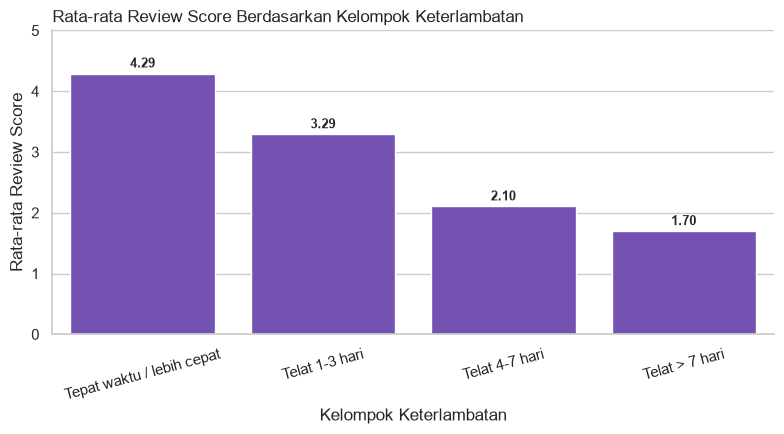

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=delay_group_stats, x="delay_group", y="avg_review", color="#6f42c1", ax=ax)
ax.set_title("Rata-rata Review Score Berdasarkan Kelompok Keterlambatan", fontsize=12, loc="left")
ax.set_xlabel("Kelompok Keterlambatan")
ax.set_ylabel("Rata-rata Review Score")
ax.set_ylim(0, 5)
for i, v in enumerate(delay_group_stats["avg_review"]):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
plt.xticks(rotation=15)
sns.despine()
plt.tight_layout()
plt.show()


**Insight (Analisis Lanjutan):**
- Analisis *binning* menunjukkan penurunan kepuasan yang terjadi secara bertahap namun langsung terasa signifikan sejak hari pertama keterlambatan:
  - Pesanan tepat waktu / lebih cepat: rata-rata review score **4,29**.
  - Keterlambatan 1–3 hari: skor langsung turun signifikan sebesar 1,00 poin menjadi **3,29**.
  - Keterlambatan 4–7 hari: skor turun lebih lanjut menjadi **2,10**.
  - Keterlambatan > 7 hari: skor anjlok ke tingkat terendah yaitu **1,70**.
- Temuan ini mengindikasikan bahwa toleransi pelanggan terhadap keterlambatan sangat rendah; bahkan keterlambatan minor (1–3 hari) sudah cukup untuk memangkas skor ulasan sebesar satu poin penuh.


## Conclusion


**Kesimpulan Pertanyaan 1 (10 Kategori Produk dengan Total Revenue Tertinggi dan Kontribusinya):**
Berdasarkan analisis terhadap transaksi pesanan berstatus *delivered* selama periode Januari 2017 – Agustus 2018 (total revenue R$ 13.179.620,86 atau sekitar R$ 13,18 juta), 10 kategori produk yang menghasilkan total revenue tertinggi beserta persentase kontribusinya secara berurutan adalah:
1. `health_beauty`: R$ 1.229.557,50 (kontribusi **9,33%**)
2. `watches_gifts`: R$ 1.163.187,91 (kontribusi **8,83%**)
3. `bed_bath_table`: R$ 1.022.955,77 (kontribusi **7,76%**)
4. `sports_leisure`: R$ 952.661,40 (kontribusi **7,23%**)
5. `computers_accessories`: R$ 887.944,60 (kontribusi **6,74%**)
6. `furniture_decor`: R$ 706.237,17 (kontribusi **5,36%**)
7. `housewares`: R$ 614.341,62 (kontribusi **4,66%**)
8. `cool_stuff`: R$ 609.158,00 (kontribusi **4,62%**)
9. `auto`: R$ 577.721,09 (kontribusi **4,38%**)
10. `garden_tools`: R$ 469.135,40 (kontribusi **3,56%**)

Secara kumulatif, 5 kategori teratas menyumbang **39,88%** dari total revenue, dan seluruh 10 kategori teratas menguasai **62,47%** (sekitar 62,5%) total revenue platform. Hal ini menunjukkan bahwa pendapatan marketplace sangat terkonsentrasi pada segelintir kategori unggulan.

**Kesimpulan Pertanyaan 2 (Keterlambatan Pengiriman per State dan Dampaknya terhadap Review Score):**
1. Dari 96.203 pesanan unik berstatus *delivered*, sebanyak 6.531 pesanan (sekitar 6,79%) mengalami keterlambatan pengiriman melebihi tanggal estimasi yang dijanjikan.
2. Tingkat keterlambatan bervariasi secara signifikan antar wilayah. Negara bagian (*state*) dengan persentase pesanan terlambat tertinggi (untuk wilayah dengan minimal 100 pesanan) didominasi oleh kawasan timur laut, yaitu:
   - **AL (Alagoas)**: 21,46% pesanan terlambat
   - **MA (Maranhão)**: 17,53% pesanan terlambat
   - **SE (Sergipe)**: 15,36% pesanan terlambat
   - **PI (Piauí)**: 13,89% pesanan terlambat
   - **CE (Ceará)**: 13,83% pesanan terlambat
   Selain wilayah timur laut, negara bagian **RJ (Rio de Janeiro)** mencatatkan keterlambatan sebesar 12,14% dengan volume pesanan yang sangat masif (12.310 pesanan).
3. Terdapat disparitas kepuasan pelanggan yang sangat kontras antara pesanan tepat waktu dan terlambat:
   - Pesanan yang tiba tepat waktu memiliki rata-rata *review score* sebesar **4,29**.
   - Pesanan yang terlambat anjlok drastis menjadi **2,27**.
   - Terjadi penurunan skor ulasan sebesar **2,02 poin** akibat keterlambatan pengiriman.
4. Korelasi Spearman antara indikator keterlambatan dengan review score adalah **-0,18**, dan antara durasi lama pengiriman dengan review score adalah **-0,23**. Arah korelasi negatif ini membuktikan bahwa durasi pengiriman yang lebih lama dan terjadinya keterlambatan secara konsisten menurunkan skor kepuasan pelanggan.

**Rekomendasi Action Item:**
1. **Fokuskan Anggaran Promosi dan Prioritas Inventaris pada 10 Kategori Unggulan (Berdasarkan Pertanyaan 1):**
   Alokasikan mayoritas anggaran promosi digital, penempatan *featured banner* di halaman utama aplikasi, dan kerja sama seller eksklusif pada 10 kategori teratas yang telah terbukti menghasilkan 62,47% pendapatan platform (khususnya 5 besar: `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories`). Untuk kategori bernilai barang tinggi seperti `watches_gifts`, sediakan promo *bundling* atau opsi cicilan fleksibel guna mendongkrak volume transaksi.
2. **Evaluasi dan Pengetatan SLA Mitra Ekspedisi di Wilayah Keterlambatan Tinggi (Berdasarkan Pertanyaan 2):**
   Lakukan evaluasi kinerja SLA secara ketat terhadap mitra logistik yang melayani rute timur laut (AL, MA, SE, PI, CE) yang memiliki tingkat keterlambatan di atas 13–21%, serta wilayah RJ yang memiliki tingkat keterlambatan 12,14% dengan beban volume pesanan tertinggi kedua setelah SP (12.310 pesanan). Bentuk jalur distribusi khusus atau pertimbangkan penambahan titik transit/mitra ekspedisi regional alternatif guna memangkas durasi pengiriman.
3. **Penerapan Sistem Peringatan Dini dan Kompensasi Proaktif untuk Pesanan Terlambat (Berdasarkan Pertanyaan 2):**
   Mengingat penurunan skor kepuasan yang sangat drastis (turun 2,02 poin ke angka 2,27 saat pesanan terlambat, dan turun 1,00 poin bahkan pada keterlambatan 1–3 hari), platform perlu mengimplementasikan notifikasi status proaktif secara otomatis kepada pembeli ketika pesanan terdeteksi berisiko terlambat. Berikan kompensasi langsung berupa voucher belanja atau diskon ongkir pada pesanan berikutnya sebagai bentuk itikad baik platform untuk memitigasi kekecewaan pelanggan dan mempertahankan retensi pembeli.


In [19]:
# Simpan data bersih untuk dashboard
os.makedirs("dashboard", exist_ok=True)
export_cols = ["order_id", "order_item_id", "price", "freight_value", "product_category_name_english",
               "order_purchase_timestamp", "order_month", "customer_state", "review_score",
               "delivery_time_days", "delivery_delay_days", "is_late"]
main_df[export_cols].to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv tersimpan:", main_df.shape[0], "baris")


main_data.csv tersimpan: 109872 baris
